In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Загрузка данных
df = pd.read_csv("../data/tips.csv")

# 2. Выделение признаков и целевой переменной (tip - размер чаевых)
X = df.drop(columns=["tip"])
y = df["tip"]

# 3. Разбиение на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Воссоздание пайплайна из ПР-3
num_features = ["total_bill", "size"]
cat_features = ["sex", "smoker", "day", "time"]

preprocessor_base = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="unknown")), 
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_features),
    ]
)

# Предобработка базового набора
X_train_base = preprocessor_base.fit_transform(X_train)
X_test_base = preprocessor_base.transform(X_test)

In [2]:
# Обучение модели на всех признаках
model_base = LinearRegression()
model_base.fit(X_train_base, y_train)

# Предсказание
y_pred_base = model_base.predict(X_test_base)

# Расчет метрик
mae_base = mean_absolute_error(y_test, y_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
r2_base = r2_score(y_test, y_pred_base)

print("МЕТРИКИ БАЗОВОЙ МОДЕЛИ:")
print(f"MAE:  {mae_base:.3f} $ (в среднем модель ошибается на эту сумму)")
print(f"RMSE: {rmse_base:.3f} $ (штрафует за крупные ошибки)")
print(f"R²:   {r2_base:.3f} (доля объясненной дисперсии)")

МЕТРИКИ БАЗОВОЙ МОДЕЛИ:
MAE:  0.667 $ (в среднем модель ошибается на эту сумму)
RMSE: 0.839 $ (штрафует за крупные ошибки)
R²:   0.437 (доля объясненной дисперсии)


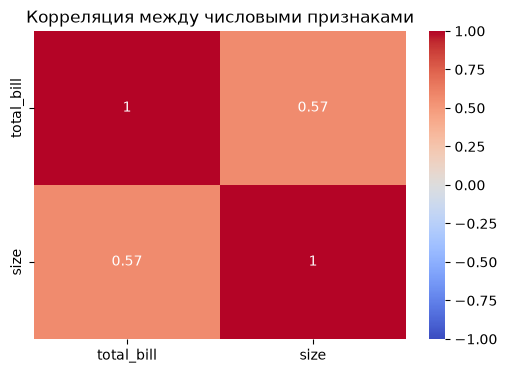

Наблюдение: total_bill и size имеют заметную корреляцию (~0.6).
Проверим, что будет, если удалить признак 'size', чтобы снизить мультиколлинеарность.


In [3]:
# Построим матрицу корреляций для числовых признаков из обучающей выборки
plt.figure(figsize=(6, 4))
sns.heatmap(X_train[num_features].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция между числовыми признаками")
plt.show()

print("Наблюдение: total_bill и size имеют заметную корреляцию (~0.6).")
print("Проверим, что будет, если удалить признак 'size', чтобы снизить мультиколлинеарность.")

In [4]:
# Оставляем только один числовой признак
num_features_reduced = ["total_bill"]

# Новый препроцессор без признака size
preprocessor_reduced = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_features_reduced),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="unknown")), 
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_features),
    ]
)

# Подготовка данных и обучение
X_train_reduced = preprocessor_reduced.fit_transform(X_train)
X_test_reduced = preprocessor_reduced.transform(X_test)

model_reduced = LinearRegression()
model_reduced.fit(X_train_reduced, y_train)
y_pred_reduced = model_reduced.predict(X_test_reduced)

# Метрики сокращенной модели
print("МЕТРИКИ СОКРАЩЕННОЙ МОДЕЛИ (без признака 'size'):")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_reduced):.3f} $")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_reduced)):.3f} $")
print(f"R²:   {r2_score(y_test, y_pred_reduced):.3f}")

МЕТРИКИ СОКРАЩЕННОЙ МОДЕЛИ (без признака 'size'):
MAE:  0.638 $
RMSE: 0.808 $
R²:   0.477


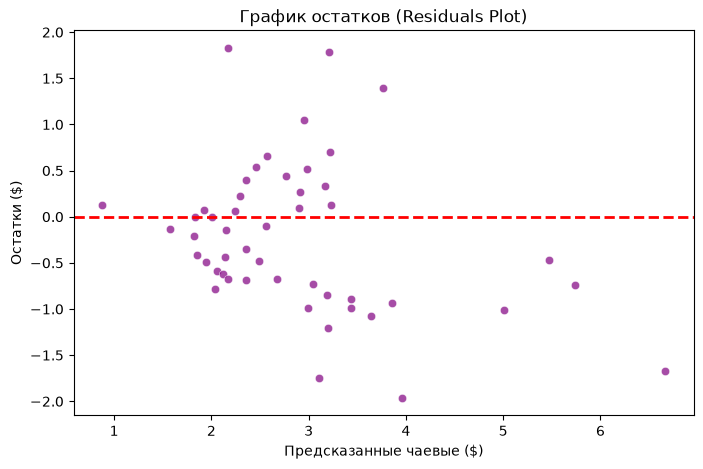

In [5]:
# Остатки = Истинные значения - Предсказанные значения (берем базовую модель)
residuals = y_test - y_pred_base

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred_base, y=residuals, alpha=0.7, color="purple")
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.title("График остатков (Residuals Plot)")
plt.xlabel("Предсказанные чаевые ($)")
plt.ylabel("Остатки ($)")
plt.show()

### Выводы по регрессионной модели:

1. **Интерпретация метрик:** Базовая модель ошибается в предсказании чаевых в среднем на **~0.67 $** (исходя из метрики MAE). Метрика RMSE немного выше (~0.89 $), что говорит о наличии нескольких крупных ошибок (выбросов), за которые RMSE штрафует сильнее.
2. **Мультиколлинеарность и выбор модели:** Корреляционный анализ показал взаимосвязь `total_bill` и `size` (r ≈ 0.6). Однако при удалении `size` (сокращенная модель) метрики немного ухудшились (MAE выросла, R² упал). Это означает, что несмотря на корреляцию, признак `size` несет уникальную полезную информацию. **Финальный выбор:** оставляем базовую модель со всеми признаками.
3. **Анализ остатков:** На графике остатков видна воронкообразная форма (гетероскедастичность) — при росте предсказанных чаевых разброс ошибок увеличивается. Это нарушает базовое допущение линейной регрессии о постоянстве дисперсии остатков. В реальности это значит, что на больших счетах предсказывать чаевые сложнее, чем на маленьких.